# HW2. Деревья и ансамбли: обучение, подбор и сравнение с HW1


## 1. Данные и разбиение

Главная метрика: macro-F1, пересчитанный под сбалансированный тест (f1_macro_bal), как в HW1: на скрытом тесте классы поровну,
а в train neutral больше половины. Рядом bal_acc (средний recall) и recall positive.
Разбиение полностью повторяет HW1: 20% диалогов (группы целиком) уходят в отложенный тест с тем же HOLDOUT_SEED,
на остальных 80% (dev) идет 5-блочная кросс-валидация по группам из задачи 14 лабораторной (группа = одинаковая первая реплика).

In [1]:
import os
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import Pipeline

from solution_utils import (
    CLASSES, NUM_COLS_ALL, TREE_NUM_COLS, TURN_AGG_COLS, StackModel, TreeModel, TurnReactionModel,
    balanced_report, build_forest, build_hist_gb, build_lgbm, build_nb_pipeline, build_reaction_pipeline,
    build_svc_pipeline, features_frame, group_ids, group_kfold_splits, init_reaction_models, predict_reaction,
    read_dialogs, read_labels, read_turn_labels, reaction_frame, save_reaction_models, turn_aggregates,
    turn_frame, turn_proba_oof, turn_targets,
)

warnings.filterwarnings("ignore")

TRAIN_PATH = os.environ.get("HW2_TRAIN")
if TRAIN_PATH is None:
    TRAIN_PATH = "data/hw1_train.jsonl"
    if not Path(TRAIN_PATH).exists():
        TRAIN_PATH = "../hw1/data/hw1_train.jsonl"

OLD_DIR = Path("../hw1/artifacts")
SEEDS = (0, 1)
SEARCH_SEEDS = (0,)
HOLDOUT_SEED = 42
print("train:", TRAIN_PATH)

train: ../hw1/data/hw1_train.jsonl


In [27]:
all_dialogs = read_dialogs(TRAIN_PATH)
lab = read_labels(TRAIN_PATH)
turn_lab = read_turn_labels(TRAIN_PATH)

L = []
y_all = []
for d in all_dialogs:
    if d["dialog_id"] in lab:
        L.append(d)
        y_all.append(lab[d["dialog_id"]])
y_all = np.array(y_all)
groups_all = group_ids(L)

t0 = time.time()
F = features_frame(L)
TF = turn_frame(L)
y_turn_all = turn_targets(TF, L, turn_lab)
print("размеченных диалогов:", len(L), " реплик:", len(TF), " признаки за", round(time.time() - t0), "сек")

dev_idx, test_idx = group_kfold_splits(groups_all, 5, seed=HOLDOUT_SEED)[0]
y_dev = y_all[dev_idx]

folds_list = {}
for s in SEEDS:
    splits = group_kfold_splits(groups_all[dev_idx], 5, seed=s)
    folds_list[s] = []
    for tr, va in splits:
        folds_list[s].append((dev_idx[tr], dev_idx[va]))

assert not set(groups_all[dev_idx]) & set(groups_all[test_idx])
pd.DataFrame({"dev": pd.Series(y_dev).value_counts(), "test": pd.Series(y_all[test_idx]).value_counts()})

размеченных диалогов: 3000  реплик: 20051  признаки за 52 сек


,dev,test
neutral,1411,363
negative,744,179
positive,245,58


## 2. Старые модели в сетапе HW2

Модели HW1 входят без изменений: те же архитектуры, class_weight="balanced". Здесь они оцениваются по тем же блокам, что и новые модели.
Своя модель hw1_custom_turn_h8 (реакция каждой реплики + правило «последняя не-neutral реплика») берет пороги из сохраненной модели HW1.

Две функции, которыми пользуемся дальше:

- cv_proba обучает модель на 4 блоках и предсказывает пятый; так собираются предсказания вне блоков (out-of-fold) для всех объектов;
- add_result считает метрики по этим предсказаниям и добавляет строку в таблицу попыток results (путь подбора).

In [3]:
results = []
OOF = {}
REPS = {}


def cv_proba(model, X, splits, how="proba", col=None):
    S = np.zeros((len(X), 3))
    for tr, va in splits:
        X_tr = X.iloc[tr]
        X_va = X.iloc[va]
        if col is not None:
            X_tr = X_tr[col]
            X_va = X_va[col]
        model.fit(X_tr, y_all[tr])
        if how == "decision":
            S[va] = model.decision_function(X_va)
        else:
            S[va] = model.predict_proba(X_va)
    return S


def add_result(name, S_list, note, t0):
    reports = []
    for S in S_list:
        pred = np.array(CLASSES)[S.argmax(axis=1)]
        reports.append(balanced_report(y_dev, pred))
    df = pd.DataFrame(reports)
    OOF[name] = S_list
    REPS[name] = reports
    row = {"модель": name, "заметка": note}
    row["f1_macro_bal"] = round(df["f1_macro_bal"].mean(), 3)
    row["std"] = round(df["f1_macro_bal"].std(ddof=0), 3)
    row["bal_acc"] = round(df["bal_acc"].mean(), 3)
    row["recall_pos"] = round(df["recall_pos"].mean(), 3)
    row["сек"] = round(time.time() - t0)
    results.append(row)
    return df["f1_macro_bal"].mean()


old_turn = joblib.load(OLD_DIR / "reaction_custom_turn_h8.joblib")
THR_NEG = old_turn.thr_neg
THR_POS = old_turn.thr_pos
print("пороги модели реплик из HW1:", THR_NEG, THR_POS)

t0 = time.time()
S_list = []
for s in SEEDS:
    S = cv_proba(build_reaction_pipeline(class_weight="balanced"), F, folds_list[s])
    S_list.append(S[dev_idx])
add_result("hw1_base_logreg", S_list, "HW1", t0)

t0 = time.time()
S_list = []
for s in SEEDS:
    S = cv_proba(build_nb_pipeline(), F, folds_list[s], col="text_user")
    S_list.append(S[dev_idx])
add_result("hw1_base_nb", S_list, "HW1", t0)

t0 = time.time()
S_list = []
for s in SEEDS:
    S = cv_proba(build_svc_pipeline(class_weight="balanced"), F, folds_list[s], how="decision")
    S_list.append(S[dev_idx])
f1 = add_result("hw1_base_svm", S_list, "HW1", t0)

пороги модели реплик из HW1: 0.5 0.3


In [4]:
t0 = time.time()
P_oof = {}
S_list = []
turn_rule = TurnReactionModel(THR_NEG, THR_POS)
for s in SEEDS:
    P_oof[s] = turn_proba_oof(TF, y_turn_all, folds_list[s])
    res = turn_rule.decide(TF, P_oof[s])
    pred = []
    for i in range(len(L)):
        pred.append(res.get(i, "neutral"))
    pred = np.array(pred)[dev_idx]
    S = np.zeros((len(pred), 3))
    for k in range(3):
        S[:, k] = (pred == CLASSES[k])
    S_list.append(S)
add_result("hw1_custom_turn_h8", S_list, "HW1", t0)
pd.DataFrame(results)

,модель,заметка,f1_macro_bal,std,bal_acc,recall_pos,сек
0,hw1_base_logreg,HW1,0.560,0.007,0.574,0.327,74
1,hw1_base_nb,HW1,0.356,0.000,0.440,0.008,13
2,hw1_base_svm,HW1,0.527,0.002,0.552,0.261,85
3,hw1_custom_turn_h8,HW1,0.649,0.005,0.648,0.594,75


## 3. Признаки для деревьев

Признаки HW1 (TF-IDF на 30 000 и 20 000 слов и биграмм плюс шкалированные числа) подходят линейным моделям, но не деревьям:

| Свойство дерева | Следствие для признаков |
|:--|:--|
| Разбиение идет по одному признаку и порогу | сотни тысяч редких разреженных столбцов TF-IDF почти не дают полезных разбиений, а случайный лес тратит max_features на шум |
| Порог не зависит от масштаба | StandardScaler не нужен, числа остаются как есть |
| Дерево находит взаимодействия само | подходят «сырые» счетчики: число реплик, длины, знаки ? и ! в последней реплике |
| Важность считается по столбцам | лучше компактная таблица (сотни столбцов), которую можно разобрать |

Поэтому для деревьев берем плотную таблицу: числовые признаки (структура диалога) и по 300 самых частых слов хвоста диалога и текста пользователя.

Своя гипотеза. В HW1 нашли правило: метка диалога = реакция последней не-neutral реплики. Линейные модели HW1 на склейке диалога его
не используют, а своя модель HW1 использует жестко. Что если дать деревьям вероятности реакций реплик (максимум, среднее, значение в последней реплике,
число реплик с вероятностью больше 0.5 и решение правила как признак), а деревья сами решат, когда им верить? Вероятности для обучающих диалогов берутся
вне блоков (turn_proba_oof) на тех же блоках, что и вся кросс-валидация, иначе дерево увидит утечку.

In [5]:
X_turn = {}
for s in SEEDS:
    agg = turn_aggregates(TF, P_oof[s], len(L), turn_rule)
    X_turn[s] = pd.concat([F, agg], axis=1)
X_plain = {}
for s in SEEDS:
    X_plain[s] = F

print("признаков деревьев: структура", len(TREE_NUM_COLS), "| агрегаты реплик", len(TURN_AGG_COLS), "| слова 2 x 300")
X_turn[0][TURN_AGG_COLS].iloc[dev_idx].groupby(y_dev).mean().round(3)

признаков деревьев: структура 14 | агрегаты реплик 10 | слова 2 x 300


,tp_neg_max,tp_pos_max,tp_neg_mean,tp_pos_mean,tp_neg_last,tp_pos_last,tp_neg_cnt,tp_pos_cnt,h8_neg,h8_pos
negative,0.612,0.155,0.329,0.058,0.445,0.085,1.805,0.069,0.602,0.066
neutral,0.330,0.141,0.160,0.058,0.220,0.094,0.329,0.036,0.183,0.085
positive,0.369,0.561,0.164,0.172,0.198,0.343,0.510,0.788,0.159,0.592


### Эксперименты с признаками (случайный лес, одни и те же параметры)

Начинаем с самого простого и по одному добавляем признаки. Первая строка воспроизводит подход HW1 на деревьях: TF-IDF 5000 слов без отбора.
Такие модели, скорее всего, проиграют HW1: это тоже результат, он объясняет, почему для деревьев признаки пришлось менять.

In [6]:
def experiment(name, model, X_by_seed, note, col=None):
    t0 = time.time()
    S_list = []
    for s in SEARCH_SEEDS:
        S = cv_proba(model, X_by_seed[s], folds_list[s], col=col)
        S_list.append(S[dev_idx])
    return add_result(name, S_list, note, t0)


tfidf_forest = Pipeline([("tfidf", TfidfVectorizer(max_features=5000, min_df=3, sublinear_tf=True)),
                         ("clf", RandomForestClassifier(n_estimators=100, class_weight="balanced", n_jobs=-1, random_state=0))])
experiment("rf_tfidf5000", tfidf_forest, X_plain, "лес на разреженном TF-IDF, как признаки HW1", col="text_user")
experiment("rf_struct7", build_forest(NUM_COLS_ALL, 0), X_plain, "только 7 структурных признаков HW1")
experiment("rf_struct14", build_forest(TREE_NUM_COLS, 0), X_plain, "+ длины, знаки, блоки кода")
experiment("rf_struct14_words", build_forest(TREE_NUM_COLS, 300), X_plain, "+ 2 x 300 слов")
experiment("rf_struct14_words_turn", build_forest(TREE_NUM_COLS + TURN_AGG_COLS, 300), X_turn, "+ агрегаты реплик (своя гипотеза)")
experiment("rf_struct14_turn_h8only", build_forest(TREE_NUM_COLS + ["h8_neg", "h8_pos"], 300), X_turn, "+ только решение правила H8")
pd.DataFrame(results[4:])

,модель,заметка,f1_macro_bal,std,bal_acc,recall_pos,сек
0,rf_tfidf5000,"лес на разреженном TF-IDF, как признаки HW1",0.522,0.0,0.534,0.318,4
1,rf_struct7,только 7 структурных признаков HW1,0.444,0.0,0.454,0.269,4
2,rf_struct14,"+ длины, знаки, блоки кода",0.447,0.0,0.472,0.200,4
3,rf_struct14_words,+ 2 x 300 слов,0.602,0.0,0.604,0.445,8
4,rf_struct14_words_turn,+ агрегаты реплик (своя гипотеза),0.653,0.0,0.652,0.543,8
5,rf_struct14_turn_h8only,+ только решение правила H8,0.633,0.0,0.632,0.518,8


Как читать таблицу. Сравниваем строки по f1_macro_bal и recall_pos (положительных реакций меньше всего, они труднее всего). Что проверяет каждая пара строк:

| Пара | Вопрос |
|:--|:--|
| rf_tfidf5000 и rf_struct14_words | нужен ли деревьям отбор слов вместо полного TF-IDF |
| rf_struct7 и rf_struct14 | помогают ли дополнительные числовые признаки |
| rf_struct14 и rf_struct14_words | дают ли слова что-то сверх структуры |
| rf_struct14_words и rf_struct14_words_turn | своя гипотеза: помогают ли деревьям реакции реплик |
| rf_struct14_words_turn и rf_struct14_turn_h8only | нужны ли вероятности или хватает решения правила H8 |

Набор признаков для следующих блоков выбирается по лучшему f1_macro_bal среди трех строк: rf_struct14, rf_struct14_words, rf_struct14_words_turn.

In [26]:
table = pd.DataFrame(results).set_index("модель")
candidates = ["rf_struct14", "rf_struct14_words", "rf_struct14_words_turn"]
best_features = table.loc[candidates, "f1_macro_bal"].idxmax()

USE_TURN = best_features.endswith("turn")
N_WORDS = 0 if best_features == "rf_struct14" else 300
if USE_TURN:
    TREE_COLS = TREE_NUM_COLS + TURN_AGG_COLS
    FRAMES = X_turn
else:
    TREE_COLS = TREE_NUM_COLS
    FRAMES = X_plain
print("лучший набор признаков:", best_features, "реакции реплик:", USE_TURN, "слов:", N_WORDS)

лучший набор признаков: rf_struct14_words_turn реакции реплик: True слов: 300


## 4. Подбор моделей

Параметры подбираются по той же кросс-валидации (поиск на SEARCH_SEEDS, чтобы уложиться во время; итоговые конфигурации потом пересчитываются на всех SEEDS).
Тест не используется. Перебор сетки сделан вложенными циклами, а не GridSearchCV, потому что нужна наша метрика f1_macro_bal и наши блоки по группам;
по смыслу это тот же перебор сетки на кросс-валидации из занятия 8.

### 4.1 Случайный лес: max_features и min_samples_leaf
чем меньше max_features, тем слабее корреляция деревьев; чем больше min_samples_leaf, тем глаже границы и меньше переобучение.

In [8]:
rf_params = [("sqrt", 1), ("sqrt", 3), ("sqrt", 5), (0.3, 1), (0.3, 3), (0.3, 5)]
rows = []
for mf, leaf in rf_params:
    model = build_forest(TREE_COLS, N_WORDS, max_features=mf, min_samples_leaf=leaf)
    name = "rf mf=" + str(mf) + " leaf=" + str(leaf)
    f1 = experiment(name, model, FRAMES, "сетка леса")
    rows.append({"max_features": mf, "min_samples_leaf": leaf, "f1_macro_bal": round(f1, 3)})
rf_grid = pd.DataFrame(rows).sort_values("f1_macro_bal", ascending=False)
best_rf = rf_grid.iloc[0]
display(rf_grid)

,max_features,min_samples_leaf,f1_macro_bal
1,sqrt,3,0.657
2,sqrt,5,0.654
0,sqrt,1,0.653
4,0.3,3,0.651
5,0.3,5,0.651
3,0.3,1,0.643


### 4.2 Гистограммный бустинг: число деревьев по валидации и сетка
у градиентного бустинга ошибка на обучении падает с каждым деревом, а на валидации сначала падает, потом растет. Число деревьев выбирают
по кривой на валидационной части (staged_predict отдает предсказание после каждого дерева). Кривая строится на одном блоке кросс-валидации:
обучающая часть блока для обучения, проверочная для оценки.

learning_rate = 0.03 | лучшее число деревьев на этом блоке: 124
learning_rate = 0.1 | лучшее число деревьев на этом блоке: 44
learning_rate = 0.3 | лучшее число деревьев на этом блоке: 4


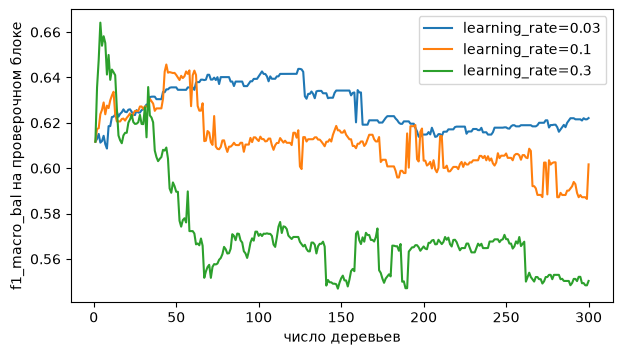

In [9]:
tr0, va0 = folds_list[0][0]
X_tr0 = FRAMES[0].iloc[tr0]
X_va0 = FRAMES[0].iloc[va0]

fig, ax = plt.subplots(figsize=(7, 3.8))
for lr in [0.03, 0.1, 0.3]:
    model = build_hist_gb(TREE_COLS, N_WORDS, learning_rate=lr, max_iter=300, early_stopping=False)
    model.fit(X_tr0, y_all[tr0])
    X_val = model[:-1].transform(X_va0)
    curve = []
    for pred in model[-1].staged_predict(X_val):
        curve.append(balanced_report(y_all[va0], pred)["f1_macro_bal"])
    ax.plot(range(1, len(curve) + 1), curve, label="learning_rate=" + str(lr))
    print("learning_rate =", lr, "| лучшее число деревьев на этом блоке:", int(np.argmax(curve)) + 1)
ax.set_xlabel("число деревьев")
ax.set_ylabel("f1_macro_bal на проверочном блоке")
ax.legend()
plt.show()

In [10]:
hgb_params = [(0.05, 3), (0.05, 5), (0.1, 3), (0.1, 5)]
rows = []
for lr, depth in hgb_params:
    model = build_hist_gb(TREE_COLS, N_WORDS, learning_rate=lr, max_depth=depth)
    name = "hist_gb lr=" + str(lr) + " depth=" + str(depth)
    f1 = experiment(name, model, FRAMES, "сетка гистограммного бустинга, ранняя остановка")
    rows.append({"learning_rate": lr, "max_depth": depth, "f1_macro_bal": round(f1, 3)})
hgb_grid = pd.DataFrame(rows).sort_values("f1_macro_bal", ascending=False)
best_hgb = hgb_grid.iloc[0]
display(hgb_grid)

,learning_rate,max_depth,f1_macro_bal
0,0.05,3,0.649
1,0.05,5,0.649
2,0.10,3,0.646
3,0.10,5,0.645


### 4.3 LightGBM: число деревьев, темп обучения, число листьев

Другая реализация градиентного бустинга (занятие 9, раздел «Библиотеки»): листья растут по лучшему приросту (leaf-wise), признаки делятся на гистограммы, а выборка
столбцов и строк для каждого дерева берется случайно (colsample_bytree, subsample). Число деревьев входит в сетку вместе с темпом обучения: меньше темп, больше деревьев.

In [11]:
lgb_params = [(7, 0.03, 150), (7, 0.03, 400), (7, 0.1, 150), (7, 0.1, 400),
              (15, 0.03, 150), (15, 0.03, 400), (15, 0.1, 150), (15, 0.1, 400)]
rows = []
for leaves, lr, n_trees in lgb_params:
    model = build_lgbm(TREE_COLS, N_WORDS, n_estimators=n_trees, learning_rate=lr, num_leaves=leaves)
    name = "lightgbm leaves=" + str(leaves) + " lr=" + str(lr) + " trees=" + str(n_trees)
    f1 = experiment(name, model, FRAMES, "сетка LightGBM")
    rows.append({"num_leaves": leaves, "learning_rate": lr, "n_estimators": n_trees, "f1_macro_bal": round(f1, 3)})
lgb_grid = pd.DataFrame(rows).sort_values("f1_macro_bal", ascending=False)
best_lgb = lgb_grid.iloc[0]
display(lgb_grid)

,num_leaves,learning_rate,n_estimators,f1_macro_bal
0,7,0.03,150,0.653
4,15,0.03,150,0.642
1,7,0.03,400,0.639
2,7,0.10,150,0.631
6,15,0.10,150,0.627
5,15,0.03,400,0.625
7,15,0.10,400,0.612
3,7,0.10,400,0.610


## 5. Стекинг и блендинг

метамодель учится на предсказаниях базовых моделей, но эти предсказания должны быть сделаны вне блоков: каждый диалог оценивает модель, обученная на остальных блоках.
Иначе метамодель увидит переобученные оценки обучающих диалогов и поверит им слишком сильно. Блоки берутся те же, что в кросс-валидации выше.

Члены ансамбля: три модели HW1 (логистическая регрессия, наивный Байес, линейный SVM) и три новые (лес, гистограммный бустинг, LightGBM).
Новые модели сначала пересчитываем с найденными параметрами на всех SEEDS: их оценки вне блоков сохраняются в OOF. Блендинг берет среднее вероятностей.
Стекинг учит логистическую регрессию на склеенных оценках.

Оговорка об утечке: оценки членов получены вне блоков, но метамодель оценивается по тем же блокам, поэтому небольшой оптимизм остается. Окончательный вывод делаем по отложенному тесту.

In [12]:
t0 = time.time()
model = build_forest(TREE_COLS, N_WORDS, max_features=best_rf["max_features"], min_samples_leaf=int(best_rf["min_samples_leaf"]))
S_list = []
for s in SEEDS:
    S = cv_proba(model, FRAMES[s], folds_list[s])
    S_list.append(S[dev_idx])
add_result("hw2_random_forest", S_list, "итоговые параметры", t0)

t0 = time.time()
model = build_hist_gb(TREE_COLS, N_WORDS, learning_rate=float(best_hgb["learning_rate"]), max_depth=int(best_hgb["max_depth"]))
S_list = []
for s in SEEDS:
    S = cv_proba(model, FRAMES[s], folds_list[s])
    S_list.append(S[dev_idx])
add_result("hw2_hist_gb", S_list, "итоговые параметры", t0)

t0 = time.time()
model = build_lgbm(TREE_COLS, N_WORDS, n_estimators=int(best_lgb["n_estimators"]),
                   learning_rate=float(best_lgb["learning_rate"]), num_leaves=int(best_lgb["num_leaves"]))
S_list = []
for s in SEEDS:
    S = cv_proba(model, FRAMES[s], folds_list[s])
    S_list.append(S[dev_idx])
add_result("hw2_lightgbm", S_list, "итоговые параметры", t0)
pd.DataFrame(results[-3:])

,модель,заметка,f1_macro_bal,std,bal_acc,recall_pos,сек
0,hw2_random_forest,итоговые параметры,0.659,0.002,0.658,0.569,16
1,hw2_hist_gb,итоговые параметры,0.653,0.004,0.652,0.582,73
2,hw2_lightgbm,итоговые параметры,0.652,0.001,0.651,0.573,21


In [ ]:
OLD3 = ["hw1_base_logreg", "hw1_base_nb", "hw1_base_svm"]
NEW3 = ["hw2_random_forest", "hw2_hist_gb", "hw2_lightgbm"]


def meta_cv(names, k, s, C):
    Z = []
    for name in names:
        Z.append(OOF[name][k])
    Z = np.hstack(Z)
    pred = np.empty(len(dev_idx), dtype=object)
    for tr, va in group_kfold_splits(groups_all[dev_idx], 5, seed=s):
        meta = LogisticRegression(C=C, class_weight="balanced", max_iter=2000)
        meta.fit(Z[tr], y_dev[tr])
        pred[va] = meta.predict(Z[va])
    return balanced_report(y_dev, pred)


def stack_reports(names, C):
    reports = []
    for k, s in enumerate(SEEDS):
        reports.append(meta_cv(names, k, s, C))
    return reports


stack_options = {"старые 3": OLD3, "новые 3": NEW3, "все 6": OLD3 + NEW3, "новые 3 + logreg": NEW3 + ["hw1_base_logreg"]}
stack_params = [("старые 3", 0.1), ("старые 3", 1.0), ("старые 3", 10.0),
                ("новые 3", 0.1), ("новые 3", 1.0), ("новые 3", 10.0),
                ("все 6", 0.1), ("все 6", 1.0), ("все 6", 10.0),
                ("новые 3 + logreg", 0.1), ("новые 3 + logreg", 1.0), ("новые 3 + logreg", 10.0)]
rows = []
for label, C in stack_params:
    df = pd.DataFrame(stack_reports(stack_options[label], C))
    rows.append({"стекинг": label, "C": C, "f1_macro_bal": round(df["f1_macro_bal"].mean(), 3),
                 "bal_acc": round(df["bal_acc"].mean(), 3), "recall_pos": round(df["recall_pos"].mean(), 3)})
stack_table = pd.DataFrame(rows).sort_values("f1_macro_bal", ascending=False)
display(stack_table)

best_stack = stack_table.iloc[0]
STACK_NAMES = stack_options[best_stack["стекинг"]]
META_C = float(best_stack["C"])
REPS["hw2_stacking"] = stack_reports(STACK_NAMES, META_C)
print("стекинг:", best_stack["стекинг"], " C =", META_C)

,стекинг,C,f1_macro_bal,bal_acc,recall_pos
6,все 6,0.1,0.660,0.659,0.620
10,новые 3 + logreg,1.0,0.659,0.658,0.624
3,новые 3,0.1,0.658,0.657,0.614
8,все 6,10.0,0.657,0.656,0.614
7,все 6,1.0,0.657,0.656,0.616
9,новые 3 + logreg,0.1,0.656,0.655,0.618
11,новые 3 + logreg,10.0,0.656,0.655,0.620
4,новые 3,1.0,0.656,0.655,0.612
5,новые 3,10.0,0.655,0.654,0.614
2,старые 3,10.0,0.621,0.621,0.576


стекинг: все 6 | C = 0.1


In [ ]:
def blend_reports(names):
    reports = []
    for k in range(len(SEEDS)):
        parts = []
        for name in names:
            parts.append(OOF[name][k])
        mean_proba = np.mean(parts, axis=0)
        reports.append(balanced_report(y_dev, np.array(CLASSES)[mean_proba.argmax(axis=1)]))
    return reports


blend_options = {"новые 3": NEW3, "новые 3 + logreg + nb": NEW3 + ["hw1_base_logreg", "hw1_base_nb"]}
rows = []
blend_all = {}
for label in blend_options:
    blend_all[label] = blend_reports(blend_options[label])
    df = pd.DataFrame(blend_all[label])
    rows.append({"блендинг": label, "f1_macro_bal": round(df["f1_macro_bal"].mean(), 3),
                 "bal_acc": round(df["bal_acc"].mean(), 3), "recall_pos": round(df["recall_pos"].mean(), 3)})
blend_table = pd.DataFrame(rows).sort_values("f1_macro_bal", ascending=False)
display(blend_table)

best_blend = blend_table.iloc[0]["блендинг"]
BLEND_NAMES = blend_options[best_blend]
REPS["hw2_blend"] = blend_all[best_blend]
print("блендинг:", best_blend)

,блендинг,f1_macro_bal,bal_acc,recall_pos
0,новые 3,0.658,0.657,0.580
1,новые 3 + logreg + nb,0.635,0.635,0.498


блендинг: новые 3


## 6. Итоговое сравнение на кросс-валидации

Одна таблица: все старые (hw1_) и новые (hw2_) модели, кросс-валидация по группам на dev, среднее по SEEDS и разброс.
Условие HW2: лучшая новая модель должна обойти лучшую старую по macro-F1 (f1_macro_bal).

In [25]:
order = ["hw1_base_logreg", "hw1_base_nb", "hw1_base_svm", "hw1_custom_turn_h8",
         "hw2_random_forest", "hw2_hist_gb", "hw2_lightgbm", "hw2_stacking", "hw2_blend"]
cv_table = {}
mean_f1 = {}
for name in order:
    df = pd.DataFrame(REPS[name])
    cv_table[name] = df.mean().round(3).astype(str) + " +- " + df.std(ddof=0).round(3).astype(str)
    mean_f1[name] = df["f1_macro_bal"].mean()
display(pd.DataFrame(cv_table).T)

best_old = "hw1_base_logreg"
best_new = "hw2_random_forest"
for name in order:
    if name.startswith("hw1_") and mean_f1[name] > mean_f1[best_old]:
        best_old = name
    if name.startswith("hw2_") and mean_f1[name] > mean_f1[best_new]:
        best_new = name
print("лучшая старая:", best_old, round(mean_f1[best_old], 3), " лучшая новая:", best_new, round(mean_f1[best_new], 3),
      " разность", round(mean_f1[best_new] - mean_f1[best_old], 3))

,f1_macro_bal,bal_acc,f1_macro_raw,recall_neg,prec_bal_neg,recall_neu,prec_bal_neu,recall_pos,prec_bal_pos
hw1_base_logreg,0.56 +- 0.007,0.574 +- 0.005,0.596 +- 0.005,0.573 +- 0.005,0.63 +- 0.012,0.822 +- 0.001,0.482 +- 0.0,0.327 +- 0.012,0.843 +- 0.003
hw1_base_nb,0.356 +- 0.0,0.44 +- 0.0,0.426 +- 0.0,0.458 +- 0.002,0.606 +- 0.002,0.855 +- 0.001,0.383 +- 0.001,0.008 +- 0.0,0.686 +- 0.061
hw1_base_svm,0.527 +- 0.002,0.552 +- 0.001,0.58 +- 0.001,0.53 +- 0.009,0.629 +- 0.0,0.863 +- 0.002,0.463 +- 0.0,0.261 +- 0.008,0.888 +- 0.003
hw1_custom_turn_h8,0.649 +- 0.005,0.648 +- 0.006,0.631 +- 0.007,0.606 +- 0.004,0.639 +- 0.001,0.743 +- 0.011,0.568 +- 0.01,0.594 +- 0.002,0.8 +- 0.003
hw2_random_forest,0.659 +- 0.002,0.658 +- 0.001,0.654 +- 0.001,0.622 +- 0.009,0.667 +- 0.008,0.781 +- 0.012,0.565 +- 0.005,0.569 +- 0.006,0.832 +- 0.001
hw2_hist_gb,0.653 +- 0.004,0.652 +- 0.004,0.639 +- 0.005,0.608 +- 0.001,0.665 +- 0.005,0.768 +- 0.004,0.567 +- 0.0,0.582 +- 0.006,0.796 +- 0.01
hw2_lightgbm,0.652 +- 0.001,0.651 +- 0.001,0.638 +- 0.001,0.619 +- 0.007,0.668 +- 0.008,0.762 +- 0.002,0.562 +- 0.002,0.573 +- 0.002,0.798 +- 0.001
hw2_stacking,0.66 +- 0.0,0.659 +- 0.0,0.63 +- 0.001,0.627 +- 0.001,0.67 +- 0.01,0.729 +- 0.0,0.581 +- 0.001,0.62 +- 0.0,0.765 +- 0.009
hw2_blend,0.658 +- 0.002,0.657 +- 0.002,0.648 +- 0.002,0.618 +- 0.003,0.674 +- 0.006,0.775 +- 0.003,0.564 +- 0.001,0.58 +- 0.0,0.817 +- 0.0


лучшая старая: hw1_custom_turn_h8 0.649  лучшая новая: hw2_stacking 0.66  разность 0.011


### Путь подбора: все попытки по порядку

Таблица results собирает все модели в том порядке, в каком они пробовались. Строки с f1_macro_bal ниже лучшей старой модели нужно объяснить в отчете:
какой признак или параметр не помогал и что поменяли дальше.

,модель,заметка,f1_macro_bal,std,bal_acc,recall_pos,сек,лучше лучшей старой
0,hw1_base_logreg,HW1,0.560,0.007,0.574,0.327,74,False
1,hw1_base_nb,HW1,0.356,0.000,0.440,0.008,13,False
2,hw1_base_svm,HW1,0.527,0.002,0.552,0.261,85,False
3,hw1_custom_turn_h8,HW1,0.649,0.005,0.648,0.594,75,False
4,rf_tfidf5000,"лес на разреженном TF-IDF, как признаки HW1",0.522,0.000,0.534,0.318,4,False
5,rf_struct7,только 7 структурных признаков HW1,0.444,0.000,0.454,0.269,4,False
6,rf_struct14,"+ длины, знаки, блоки кода",0.447,0.000,0.472,0.200,4,False
7,rf_struct14_words,+ 2 x 300 слов,0.602,0.000,0.604,0.445,8,False
8,rf_struct14_words_turn,+ агрегаты реплик (своя гипотеза),0.653,0.000,0.652,0.543,8,True
9,rf_struct14_turn_h8only,+ только решение правила H8,0.633,0.000,0.632,0.518,8,False


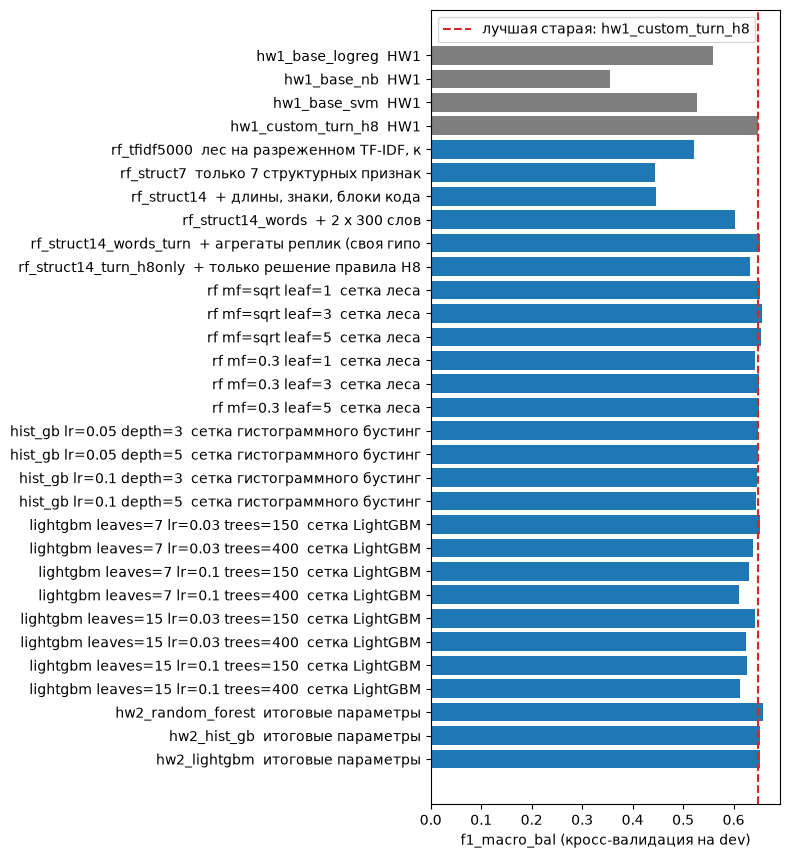

In [16]:
path = pd.DataFrame(results)
path["лучше лучшей старой"] = path["f1_macro_bal"] > mean_f1[best_old]
display(path)

colors = []
for name in path["модель"]:
    if name.startswith("hw1_"):
        colors.append("tab:gray")
    else:
        colors.append("tab:blue")

fig, ax = plt.subplots(figsize=(8, max(3, 0.28 * len(path))))
ax.barh(path["модель"] + "  " + path["заметка"].str[:28], path["f1_macro_bal"], color=colors)
ax.axvline(mean_f1[best_old], color="tab:red", ls="--", label="лучшая старая: " + best_old)
ax.invert_yaxis()
ax.set_xlabel("f1_macro_bal (кросс-валидация на dev)")
ax.legend()
plt.tight_layout()
plt.show()

## 7. тест

Новые модели обучаются на dev функцией fit_new_models (она же потом обучает финальные модели на всех 3000 диалогов). Шаги внутри:

1. модель реплик обучается на всех диалогах из idx (для применения) и вне блоков (для признаков деревьев);
2. деревья обучаются на таблице признаков с агрегатами вне блоков;
3. оценки всех членов вне блоков на тех же блоках, метамодель стекинга учится на них.

Старые модели переобучаются на dev теми же архитектурами. Предсказания строятся через predict_reaction из «сырых» диалогов, то есть так же, как это сделает solution.ipynb.

In [ ]:
def fit_new_models(idx):
    splits = []
    for tr, va in group_kfold_splits(groups_all[idx], 5, seed=0):
        splits.append((idx[tr], idx[va]))

    rows = np.where(np.isin(TF["dialog_idx"].values, idx))[0]
    turn_model = TurnReactionModel(THR_NEG, THR_POS).fit_frame(TF.iloc[rows], y_turn_all[rows])
    if USE_TURN:
        P = turn_proba_oof(TF, y_turn_all, splits)
        X = pd.concat([F, turn_aggregates(TF, P, len(L), turn_model)], axis=1)
        turn_for_trees = turn_model
    else:
        X = F
        turn_for_trees = None

    logreg = build_reaction_pipeline(class_weight="balanced")
    nb = build_nb_pipeline()
    svm = build_svc_pipeline(class_weight="balanced")
    forest = build_forest(TREE_COLS, N_WORDS, max_features=best_rf["max_features"],
                          min_samples_leaf=int(best_rf["min_samples_leaf"]))
    hist_gb = build_hist_gb(TREE_COLS, N_WORDS, learning_rate=float(best_hgb["learning_rate"]),
                            max_depth=int(best_hgb["max_depth"]))
    lgbm = build_lgbm(TREE_COLS, N_WORDS, n_estimators=int(best_lgb["n_estimators"]),
                      learning_rate=float(best_lgb["learning_rate"]), num_leaves=int(best_lgb["num_leaves"]))

    oof = {}
    oof["hw1_base_logreg"] = cv_proba(logreg, X, splits)
    oof["hw1_base_nb"] = cv_proba(nb, X, splits, col="text_user")
    oof["hw1_base_svm"] = cv_proba(svm, X, splits, how="decision")
    oof["hw2_random_forest"] = cv_proba(forest, X, splits)
    oof["hw2_hist_gb"] = cv_proba(hist_gb, X, splits)
    oof["hw2_lightgbm"] = cv_proba(lgbm, X, splits)

    logreg.fit(X.iloc[idx], y_all[idx])
    nb.fit(X["text_user"].iloc[idx], y_all[idx])
    svm.fit(X.iloc[idx], y_all[idx])
    forest.fit(X.iloc[idx], y_all[idx])
    hist_gb.fit(X.iloc[idx], y_all[idx])
    lgbm.fit(X.iloc[idx], y_all[idx])

    members = {"hw1_base_logreg": (logreg, "proba"), "hw1_base_nb": (nb, "text"), "hw1_base_svm": (svm, "decision"),
               "hw2_random_forest": (forest, "proba"), "hw2_hist_gb": (hist_gb, "proba"), "hw2_lightgbm": (lgbm, "proba")}

    Z = []
    stack_members = []
    for name in STACK_NAMES:
        Z.append(oof[name][idx])
        stack_members.append(members[name])
    meta = LogisticRegression(C=META_C, class_weight="balanced", max_iter=2000)
    meta.fit(np.hstack(Z), y_all[idx])

    blend_members = []
    for name in BLEND_NAMES:
        blend_members.append(members[name])

    result = {}
    result["hw2_random_forest"] = TreeModel(forest, turn_for_trees)
    result["hw2_hist_gb"] = TreeModel(hist_gb, turn_for_trees)
    result["hw2_lightgbm"] = TreeModel(lgbm, turn_for_trees)
    result["hw2_stacking"] = StackModel(stack_members, meta, turn_for_trees)
    result["hw2_blend"] = StackModel(blend_members, None, turn_for_trees)
    return result

In [18]:
test_dialogs = []
for i in test_idx:
    test_dialogs.append(L[i])
y_test = y_all[test_idx]

holdout_models = {}
holdout_models["hw1_base_logreg"] = build_reaction_pipeline(class_weight="balanced").fit(F.iloc[dev_idx], y_dev)
holdout_models["hw1_base_nb"] = build_nb_pipeline().fit(F["text_user"].iloc[dev_idx], y_dev)
holdout_models["hw1_base_svm"] = build_svc_pipeline(class_weight="balanced").fit(F.iloc[dev_idx], y_dev)
dev_rows = np.where(np.isin(TF["dialog_idx"].values, dev_idx))[0]
holdout_models["hw1_custom_turn_h8"] = TurnReactionModel(THR_NEG, THR_POS).fit_frame(TF.iloc[dev_rows], y_turn_all[dev_rows])
holdout_models.update(fit_new_models(dev_idx))

holdout_pred = {}
holdout_rows = {}
for name in order:
    holdout_pred[name] = np.array(predict_reaction(holdout_models[name], test_dialogs))
    holdout_rows[name] = balanced_report(y_test, holdout_pred[name])
holdout_table = pd.DataFrame(holdout_rows).T
display(holdout_table.round(3))

ho_old = "hw1_base_logreg"
ho_new = "hw2_random_forest"
for name in order:
    if name.startswith("hw1_") and holdout_table.loc[name, "f1_macro_bal"] > holdout_table.loc[ho_old, "f1_macro_bal"]:
        ho_old = name
    if name.startswith("hw2_") and holdout_table.loc[name, "f1_macro_bal"] > holdout_table.loc[ho_new, "f1_macro_bal"]:
        ho_new = name
diff = holdout_table.loc[ho_new, "f1_macro_bal"] - holdout_table.loc[ho_old, "f1_macro_bal"]
print("отложенный тест: лучшая старая", ho_old, round(holdout_table.loc[ho_old, "f1_macro_bal"], 3),
      "| лучшая новая", ho_new, round(holdout_table.loc[ho_new, "f1_macro_bal"], 3), "| разность", round(diff, 3))

,f1_macro_bal,bal_acc,f1_macro_raw,recall_neg,prec_bal_neg,recall_neu,prec_bal_neu,recall_pos,prec_bal_pos
hw1_base_logreg,0.572,0.583,0.607,0.609,0.694,0.813,0.464,0.328,0.881
hw1_base_nb,0.350,0.435,0.419,0.464,0.638,0.840,0.370,0.000,0.000
hw1_base_svm,0.539,0.559,0.589,0.564,0.721,0.854,0.443,0.259,0.894
hw1_custom_turn_h8,0.656,0.654,0.625,0.620,0.633,0.722,0.589,0.621,0.780
hw2_random_forest,0.686,0.686,0.680,0.637,0.705,0.818,0.598,0.603,0.828
hw2_hist_gb,0.673,0.673,0.638,0.609,0.721,0.771,0.599,0.638,0.735
hw2_lightgbm,0.693,0.693,0.658,0.626,0.734,0.780,0.615,0.672,0.763
hw2_stacking,0.682,0.682,0.634,0.626,0.716,0.730,0.611,0.690,0.741
hw2_blend,0.696,0.696,0.671,0.631,0.738,0.802,0.611,0.655,0.786


отложенный тест: лучшая старая hw1_custom_turn_h8 0.656 | лучшая новая hw2_blend 0.696 | разность 0.041


### Матрицы ошибок: лучшая новая и лучшая старая модель

Выбираем по кросс-валидации (best_new, best_old), а не по отложенному тесту, чтобы не подгонять выбор под него.

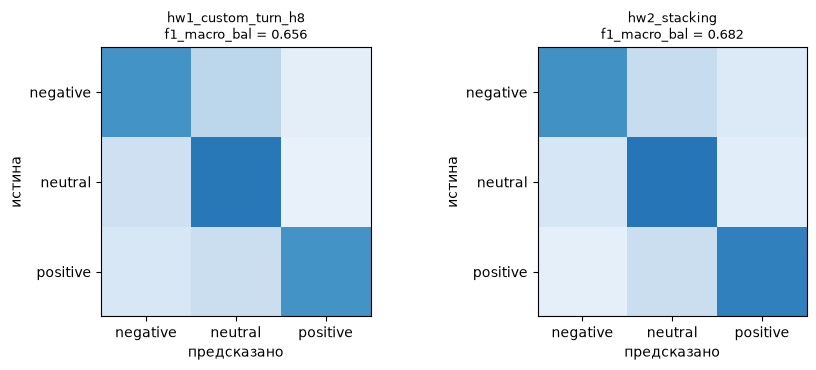

hw1_custom_turn_h8
          negative  neutral  positive
negative       111       50        18
neutral         74      262        27
positive         9       13        36
hw2_stacking
          negative  neutral  positive
negative       112       43        24
neutral         59      265        39
positive         5       13        40


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
two_models = [best_old, best_new]
for k in range(2):
    name = two_models[k]
    cm = confusion_matrix(y_test, holdout_pred[name], labels=CLASSES)
    axes[k].imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    axes[k].set_xticks(range(3))
    axes[k].set_xticklabels(CLASSES)
    axes[k].set_yticks(range(3))
    axes[k].set_yticklabels(CLASSES)
    axes[k].set_title(name + "\nf1_macro_bal = " + str(round(holdout_table.loc[name, "f1_macro_bal"], 3)), fontsize=9)
    axes[k].set_xlabel("предсказано")
    axes[k].set_ylabel("истина")
plt.tight_layout()
plt.show()
for name in two_models:
    print(name)
    print(pd.DataFrame(confusion_matrix(y_test, holdout_pred[name], labels=CLASSES), index=CLASSES, columns=CLASSES))

### Диалоги, где новая модель исправила ошибку старой и где ошиблась там, где старая была права

In [28]:
new_p = holdout_pred[best_new]
old_p = holdout_pred[best_old]
fixed = np.where((new_p == y_test) & (old_p != y_test))[0]
broken = np.where((new_p != y_test) & (old_p == y_test))[0]
both_wrong = int(((new_p != y_test) & (old_p != y_test)).sum())
print("новая исправила ошибку старой:", len(fixed), " новая ошиблась там, где старая права:", len(broken), " обе ошиблись:", both_wrong)


def show(positions, title):
    print(title)
    for j in positions[:4]:
        d = test_dialogs[j]
        turns = d["turns"]
        last_u = 0
        for i in range(len(turns)):
            if turns[i]["role"] == "user":
                last_u = i
        print()
        print("[" + d["dialog_id"] + "] истина:", y_test[j], "|", best_old + ":", old_p[j], "|", best_new + ":", new_p[j])
        print("  реакции реплик (разметка):", turn_lab[d["dialog_id"]])
        if last_u > 0:
            print("  ассистент перед последней репликой:", repr(turns[last_u - 1]["text"][:160]))
        print("  последняя user-реплика:", repr(turns[last_u]["text"][:200]))


show(fixed, "исправлео новой моделью")
show(broken, "сломано новой моделью")

новая исправила ошибку старой: 41  новая ошиблась там, где старая права: 33  обе ошиблись: 150
исправлео новой моделью

[d7a6280ce8e] истина: negative | hw1_custom_turn_h8: positive | hw2_stacking: negative
  реакции реплик (разметка): ['neutral', 'neutral', 'neutral', 'neutral', 'negative', 'negative', 'negative', 'neutral']
  ассистент перед последней репликой: 'I apologize for the confusion in my previous responses. Without more context about the specific food you are referring to, I am unable to provide a clear answer'
  последняя user-реплика: 'how many masses we have on spectrometer'

[d1666f4cf5e] истина: neutral | hw1_custom_turn_h8: negative | hw2_stacking: neutral
  реакции реплик (разметка): ['neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral']
  ассистент перед последней репликой: "Sure, here's an edited version for publication in indexed reviews:\n\nAccurately depicting the extent of paleoclimate change in the wester

## 8. Важность признаков лучшего леса

Два способа для случайного леса (занятие 8):

| Способ | Что измеряет | Известные слабости |
|:--|:--|:--|
| MDI (feature_importances_) | суммарное уменьшение неоднородности от разбиений по признаку в обучающей выборке | завышает непрерывные признаки с большим числом порогов (длины, TF-IDF), считается на обучении, делит важность между коррелированными |
| Перестановочная важность (permutation_importance) | падение качества на отложенных данных, если перемешать столбец | коррелированные признаки страхуют друг друга и обе кажутся неважными, шумная при малой выборке |

Перестановочная важность считается на отложенном тесте, метрика f1_macro (для оценки важности достаточно обычной).

In [21]:
rf_model = holdout_models["hw2_random_forest"]
X_test_frame = reaction_frame(test_dialogs, rf_model.turn_model)
prep = rf_model.pipe[:-1]
forest = rf_model.pipe[-1]
X_test_dense = prep.transform(X_test_frame)
names = []
for n in prep.get_feature_names_out():
    names.append(n.replace("num__", ""))

perm = permutation_importance(forest, X_test_dense, y_test, scoring="f1_macro", n_repeats=10, random_state=0, n_jobs=1)
imp = pd.DataFrame({"MDI": forest.feature_importances_, "перестановочная": perm.importances_mean}, index=names)
print("Spearman между MDI и перестановочной важностью:", round(imp["MDI"].corr(imp["перестановочная"], method="spearman"), 3))
display(imp.sort_values("MDI", ascending=False).head(15).round(4))
display(imp.sort_values("перестановочная", ascending=False).head(15).round(4))

Spearman между MDI и перестановочной важностью: 0.167


,MDI,перестановочная
tp_pos_max,0.0579,0.0157
tp_pos_mean,0.0463,0.0081
tp_neg_mean,0.0402,0.0106
user__thank,0.0340,0.0141
tp_neg_max,0.0326,0.0046
h8_pos,0.0325,0.0151
tp_pos_cnt,0.0323,0.0027
tp_pos_last,0.0292,0.0000
tp_neg_last,0.0259,0.0006
tp_neg_cnt,0.0246,0.0064


,MDI,перестановочная
tail__apolog,0.0142,0.0198
tp_pos_max,0.0579,0.0157
h8_pos,0.0325,0.0151
user__thank,0.0340,0.0141
tp_neg_mean,0.0402,0.0106
tp_pos_mean,0.0463,0.0081
tp_neg_cnt,0.0246,0.0064
asst_words,0.0133,0.0062
tp_neg_max,0.0326,0.0046
tail__natur,0.0007,0.0045


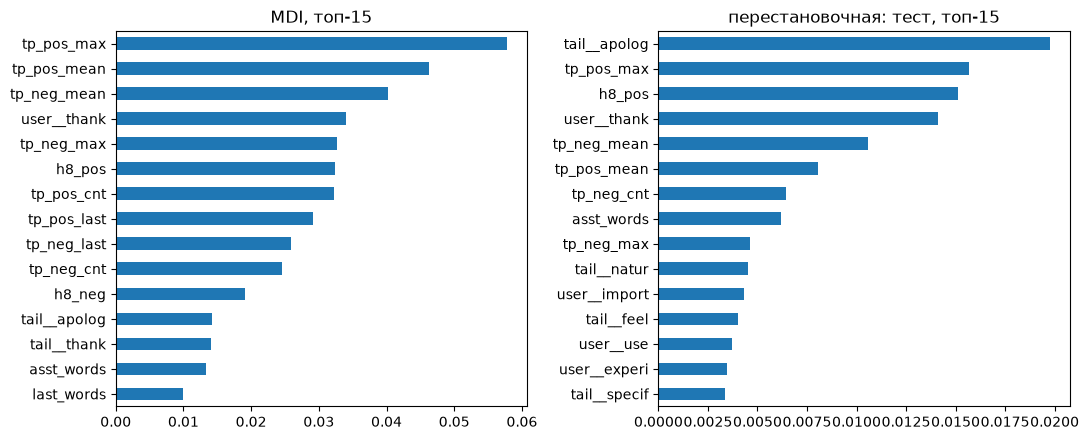

,MDI,перестановочная
агрегаты реплик,0.3405,0.0573
слова пользователя,0.3301,0.0351
слова хвоста,0.2463,0.0360
структура,0.0831,0.0018


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
imp["MDI"].sort_values().tail(15).plot.barh(ax=axes[0], title="MDI, топ-15")
imp["перестановочная"].sort_values().tail(15).plot.barh(ax=axes[1], title="перестановочная: тест, топ-15")
plt.tight_layout(); plt.show()

group_of = []
for n in imp.index:
    if n.startswith("tail__"):
        group_of.append("слова хвоста")
    elif n.startswith("user__"):
        group_of.append("слова пользователя")
    elif n in TURN_AGG_COLS:
        group_of.append("агрегаты реплик")
    else:
        group_of.append("структура")
display(imp.groupby(group_of).sum().round(4))

## 9. Финальное обучение и сохранение в artifacts/

Отложенный тест уже использован, поэтому новые модели обучаются на всех 3000 размеченных диалогов. Старые модели HW1 копируются из ../hw1/artifacts/ без изменений
под именами hw1_* (по префиксу проверка отделяет старые модели от новых).

In [31]:
final_models = fit_new_models(np.arange(len(L)))
old_files = {"reaction_base_logreg": "hw1_base_logreg", "reaction_base_nb": "hw1_base_nb",
             "reaction_base_svm": "hw1_base_svm", "reaction_custom_turn_h8": "hw1_custom_turn_h8"}
for old_name in old_files:
    final_models[old_files[old_name]] = joblib.load(OLD_DIR / (old_name + ".joblib"))
save_reaction_models(final_models)

loaded = init_reaction_models()
sample = L[:200]
for name in final_models:
    assert predict_reaction(final_models[name], sample) == predict_reaction(loaded[name], sample), name
print("artifacts сохранены:", list(loaded))

for p in sorted(Path("artifacts").glob("*.joblib")):
    print(p.name, round(p.stat().st_size / 1e6, 1), "МБ")

artifacts сохранены: ['hw1_base_logreg', 'hw1_base_nb', 'hw1_base_svm', 'hw1_custom_turn_h8', 'hw2_random_forest', 'hw2_hist_gb', 'hw2_lightgbm', 'hw2_stacking', 'hw2_blend']
hw1_base_logreg.joblib 0.9 МБ
hw1_base_nb.joblib 0.2 МБ
hw1_base_svm.joblib 0.9 МБ
hw1_custom_turn_h8.joblib 1.4 МБ
hw2_blend.joblib 6.9 МБ
hw2_hist_gb.joblib 2.3 МБ
hw2_lightgbm.joblib 1.8 МБ
hw2_random_forest.joblib 6.1 МБ
hw2_stacking.joblib 12.3 МБ
